In [2]:
import json

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [3]:
sim_dir = "/Users/z5114326/Documents/simulations/"
# sim_dir = "/Volumes/Expansion/simulations/"
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]

sim_codes = sim_dir + "simulation_codes.json"
with open(sim_codes) as sim_json:
    sim_data = json.load(sim_json)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

mw_gcs_path = "../data/mw_gcs/mw_gcs.csv"
mw_gcs = pd.read_csv(mw_gcs_path)

m12b: M_63.7 = 2.43e+04 Msun
m12c: M_63.7 = 2.43e+04 Msun
m12f: M_63.7 = 2.41e+04 Msun
m12i: M_63.7 = 2.42e+04 Msun
m12m: M_63.7 = 2.44e+04 Msun


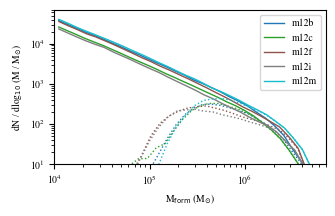

In [4]:
nbins = 30

# fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.0))

mean_all_dict = {}
centers_dict = {}
dlogM_dict = {}

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    # --- gather ALL masses for binning (still use full sample) ---
    all_m = []
    for it_id in ghost_data.keys():
        m = 10 ** ghost_data[it_id]["source"]["logm_tfor"][()]
        all_m.append(m)
    all_m = np.concatenate(all_m)

    bins = np.logspace(np.log10(all_m.min()), np.log10(all_m.max()), nbins)
    centers = np.sqrt(bins[1:] * bins[:-1])
    dlogM = np.log10(bins[1:]) - np.log10(bins[:-1])

    hist_all = []
    hist_surv = []

    for it_id in ghost_data.keys():
        src = ghost_data[it_id]["source"]

        m_all = 10 ** src["logm_tfor"][()]
        smsk = src["s_flag"][()].astype(bool)
        m_surv = m_all[smsk]

        # --- full population ---
        counts_all, _ = np.histogram(m_all, bins=bins)
        hist_all.append(counts_all / dlogM)

        # --- surviving population ---
        counts_surv, _ = np.histogram(m_surv, bins=bins)
        hist_surv.append(counts_surv / dlogM)

    hist_all = np.array(hist_all)
    hist_surv = np.array(hist_surv)

    mean_all = np.mean(hist_all, axis=0)
    mean_surv = np.mean(hist_surv, axis=0)

    mean_all_dict[sim] = mean_all
    centers_dict[sim] = centers
    dlogM_dict[sim] = dlogM

    # --- plots ---
    ax.plot(centers, mean_all, label=sim, c=sim_colors[sim], ls="-", lw=1)
    ax.plot(centers, mean_surv, c=sim_colors[sim], ls=":", lw=1)

    cumN = np.cumsum(mean_all * dlogM)
    cumN /= cumN[-1]

    M63 = np.interp(0.637, cumN, centers)
    # ax.axvline(M63, color="r", ls="--", alpha=0.5)
    print(f"{sim}: M_63.7 = {M63:.2e} Msun")


# mw_gc_for = 10 ** np.array(mw_gcs["log_mini"])
# counts_mw, _ = np.histogram(mw_gc_for, bins=bins)
# ax.plot(centers, counts_mw, c="magenta", ls="--", label="Milky Way")

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"M$_{\mathrm{form}}$ (M$_{\odot}$)")
ax.set_ylabel(r"dN / dlog$_{10}$ (M / M$_{\odot}$)")

ax.set_xlim([10**4, 7 * 10**6])
ax.set_ylim([10**1, 7 * 10**4])

ax.legend()

save_name = "../data/figures/gc_plots/gc_icmf.pdf"
fig.savefig(save_name, bbox_inches="tight")

# ax.axvline(10**5)
# ax.axvline(5 * 10**5)

plt.show()

In [5]:
nsamp = 1000
nreal = 10000

for sim in sim_lst:
    mean_all = mean_all_dict[sim]
    centers = centers_dict[sim]
    dlogM = dlogM_dict[sim]

    # convert dN/dlogM into a probability distribution
    pdf = mean_all * dlogM
    pdf /= pdf.sum()

    # exact 64th percentile of the parent distribution
    cdf = np.cumsum(pdf)
    M64_true = np.interp(0.50, cdf, centers)

    # Monte Carlo: repeatedly draw 100 clusters
    M64_samples = np.empty(nreal)

    for i in range(nreal):
        draw = np.random.choice(centers, size=nsamp, replace=True, p=pdf)

        M64_samples[i] = np.percentile(draw, 50)

    print(f"\n{sim}")
    print(f"Parent distribution M64 = {M64_true:.2e} Msun")
    print(
        f"100-cluster realizations: "
        f"{np.median(np.log10(M64_samples)):.2e} "
        f"[{np.percentile(M64_samples, 16):.2e}, "
        f"{np.percentile(M64_samples, 84):.2e}] Msun"
    )



m12b
Parent distribution M64 = 1.77e+04 Msun
100-cluster realizations: 4.33e+00 [1.72e+04, 2.14e+04] Msun

m12c
Parent distribution M64 = 1.77e+04 Msun
100-cluster realizations: 4.33e+00 [1.91e+04, 2.12e+04] Msun

m12f
Parent distribution M64 = 1.75e+04 Msun
100-cluster realizations: 4.34e+00 [1.74e+04, 2.18e+04] Msun

m12i
Parent distribution M64 = 1.76e+04 Msun
100-cluster realizations: 4.33e+00 [1.73e+04, 2.15e+04] Msun

m12m
Parent distribution M64 = 1.78e+04 Msun
100-cluster realizations: 4.33e+00 [1.72e+04, 2.14e+04] Msun


In [6]:
# nbins = 20

# fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))

# for sim in sim_lst:
#     ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
#     ghost_data = h5py.File(ghost_file, "r")

#     # --- gather ALL masses for binning (still use full sample) ---

#     bins = np.logspace(1, 7, nbins)
#     centers = np.sqrt(bins[1:] * bins[:-1])
#     dlogM = np.log10(bins[1:]) - np.log10(bins[:-1])

#     hist_surv = []

#     for it_id in ghost_data.keys():
#         src = ghost_data[it_id]["source"]

#         m_all = 10 ** src["logm_tz0"][()]
#         smsk = src["s_flag"][()].astype(bool)
#         m_surv = m_all[smsk]

#         # --- surviving population ---
#         counts_surv, _ = np.histogram(m_surv, bins=bins)
#         hist_surv.append(counts_surv / dlogM)

#     hist_surv = np.array(hist_surv)
#     mean_surv = np.mean(hist_surv, axis=0)

#     # --- plots ---
#     ax.plot(centers, mean_surv, c=sim_colors[sim], ls="--", label=sim)

# mw_gc_z0 = np.array(mw_gcs["mass"])
# counts_mw, _ = np.histogram(mw_gc_z0, bins=bins)
# ax.plot(centers, counts_mw, c="magenta", ls="--", label="Milky Way")

# ax.set_xscale("log")
# ax.set_yscale("log")

# ax.set_xlabel(r"M$_{z=0}$ [M$_{\odot}$]")
# ax.set_ylabel(r"dN / dlog$_{10}$ (M / M$_{\odot}$)")

# ax.set_xlim([10**1, 7 * 10**6])
# ax.set_ylim([10**-1, 3 * 10**2])

# ax.legend()

# save_name = "../data/figures/gc_plots/gc_mf_z0.pdf"
# fig.savefig(save_name, bbox_inches="tight")

# plt.show()

In [7]:
# fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(8, 10))

# ##########################################################################################

# nbins = 30
# for sim in sim_lst:
#     ax = axs[0]

#     ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
#     ghost_data = h5py.File(ghost_file, "r")

#     # --- gather ALL masses for binning (still use full sample) ---
#     all_m = []
#     for it_id in ghost_data.keys():
#         m = 10 ** ghost_data[it_id]["source"]["logm_tfor"][()]
#         all_m.append(m)
#     all_m = np.concatenate(all_m)

#     bins = np.logspace(np.log10(all_m.min()), np.log10(all_m.max()), nbins)
#     centers = np.sqrt(bins[1:] * bins[:-1])
#     dlogM = np.log10(bins[1:]) - np.log10(bins[:-1])

#     hist_all = []
#     hist_surv = []

#     for it_id in ghost_data.keys():
#         src = ghost_data[it_id]["source"]

#         m_all = 10 ** src["logm_tfor"][()]
#         smsk = src["s_flag"][()].astype(bool)
#         m_surv = m_all[smsk]

#         # --- full population ---
#         counts_all, _ = np.histogram(m_all, bins=bins)
#         hist_all.append(counts_all / dlogM)

#         # --- surviving population ---
#         counts_surv, _ = np.histogram(m_surv, bins=bins)
#         hist_surv.append(counts_surv / dlogM)

#     hist_all = np.array(hist_all)
#     hist_surv = np.array(hist_surv)

#     mean_all = np.mean(hist_all, axis=0)
#     mean_surv = np.mean(hist_surv, axis=0)

#     # --- plots ---
#     ax.plot(centers, mean_all, label=sim, c=sim_colors[sim], ls="-")
#     ax.plot(centers, mean_surv, c=sim_colors[sim], ls=":")


# # mw_gc_for = 10 ** np.array(mw_gcs["log_mini"])
# # counts_mw, _ = np.histogram(mw_gc_for, bins=bins)
# # ax.plot(centers, counts_mw, c="magenta", ls="--", label="Milky Way")

# ax.set_xscale("log")
# ax.set_yscale("log")

# ax.set_xlabel(r"M$_{\mathrm{formation}}$ (M$_{\odot}$)")
# ax.set_ylabel(r"dN / dlog$_{10}$ (M / M$_{\odot}$)")

# ax.set_xlim([10**4, 7 * 10**6])
# ax.set_ylim([10**1, 7 * 10**4])

# ax.legend()

# ##########################################################################################

# nbins = 20
# for sim in sim_lst:
#     ax = axs[1]

#     ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
#     ghost_data = h5py.File(ghost_file, "r")

#     # --- gather ALL masses for binning (still use full sample) ---

#     bins = np.logspace(1, 7, nbins)
#     centers = np.sqrt(bins[1:] * bins[:-1])
#     dlogM = np.log10(bins[1:]) - np.log10(bins[:-1])

#     hist_surv = []

#     for it_id in ghost_data.keys():
#         src = ghost_data[it_id]["source"]

#         m_all = 10 ** src["logm_tz0"][()]
#         smsk = src["s_flag"][()].astype(bool)
#         m_surv = m_all[smsk]

#         # --- surviving population ---
#         counts_surv, _ = np.histogram(m_surv, bins=bins)
#         hist_surv.append(counts_surv / dlogM)

#     hist_surv = np.array(hist_surv)
#     mean_surv = np.mean(hist_surv, axis=0)

#     # --- plots ---
#     # ax.plot(centers, mean_surv, c=sim_colors[sim], ls="--", label=sim)
#     ax.plot(centers, mean_surv, c=sim_colors[sim], ls="--")

# mw_gc_z0 = np.array(mw_gcs["mass"])
# counts_mw, _ = np.histogram(mw_gc_z0, bins=bins)
# ax.plot(centers, counts_mw, c="magenta", ls="--", label="Milky Way")

# ax.set_xscale("log")
# ax.set_yscale("log")

# ax.set_xlabel(r"M$_{z=0}$ (M$_{\odot}$)")
# ax.set_ylabel(r"dN / dlog$_{10}$ (M / M$_{\odot}$)")

# ax.set_xlim([10**1, 7 * 10**6])
# ax.set_ylim([10**-1, 3 * 10**2])

# ax.legend(loc="upper left")

# ##########################################################################################

# save_name = "../data/figures/gc_plots/gc_mass_functions.pdf"
# fig.savefig(save_name, bbox_inches="tight")

# plt.show()